# Full Dataset EDA — Big-Vul

This notebook explores the **complete** Big-Vul dataset (`data/bigvul.csv`) to understand CVE/CWE coverage and data distribution before expanding the POC beyond CWE-119.

**Prerequisite:** Run `dvc repro data_ingestion` to download `data/bigvul.csv` if it does not exist.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sys.path.insert(0, str(Path.cwd().parent))

from graph_vul.config import BIGVUL_CSV
from graph_vul.pipeline.extract_subset import _read_bigvul_csv

sns.set_theme(style="whitegrid")
%matplotlib inline

In [2]:
# Load the full Big-Vul dataset (handles ZIP-compressed files)
df = _read_bigvul_csv(str(BIGVUL_CSV))

# Verify expected columns exist
required_cols = {"func_before", "cve_id", "vul"}
missing = required_cols - set(df.columns)
if missing:
    raise ValueError(f"Missing expected columns: {missing}. Available: {list(df.columns)}")

print(f"Loaded {len(df):,} rows, {len(df.columns)} columns")
print(f"\nColumns: {list(df.columns)}")

/Users/noamc/repos/graph-vul/graph_vul/pipeline/extract_subset.py:19: DtypeWarning: Columns (1,20,22,23,27,28,29) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(src, compression="zip")


Loaded 188,636 rows, 36 columns

Columns: ['Unnamed: 0', 'Access Gained', 'Attack Origin', 'Authentication Required', 'Availability', 'cve_id', 'CVE Page', 'cwe_id', 'Complexity', 'Confidentiality', 'Integrity', 'Known Exploits', 'Publish Date', 'Score', 'cve_desc', 'Update Date', 'Vulnerability Classification', 'add_lines', 'codeLink', 'commit_id', 'commit_message', 'del_lines', 'file_name', 'files_changed', 'func_after', 'func_before', 'lang', 'lines_after', 'lines_before', 'parentID', 'patch', 'project', 'project_after', 'project_before', 'vul', 'vul_func_with_fix']


## 1. Dataset Overview

In [3]:
print(f"Total samples: {len(df):,}")
print(f"\nClass distribution:")
counts = df["vul"].value_counts()
for label, count in sorted(counts.items()):
    name = "vulnerable" if label == 1 else "benign"
    print(f"  {name} ({label}): {count:,} ({count / len(df) * 100:.1f}%)")

print(f"\nUnique CVE IDs: {df['cve_id'].nunique():,}")
if "cwe_id" in df.columns:
    print(f"Unique CWE IDs: {df['cwe_id'].nunique():,}")

Total samples: 188,636

Class distribution:
  benign (0): 177,736 (94.2%)
  vulnerable (1): 10,900 (5.8%)

Unique CVE IDs: 3,539
Unique CWE IDs: 91


In [4]:
df.head()

,Unnamed: 0,Access Gained,Attack Origin,Authentication Required,Availability,cve_id,CVE Page,cwe_id,Complexity,Confidentiality,...,lang,lines_after,lines_before,parentID,patch,project,project_after,project_before,vul,vul_func_with_fix
0,0,NaN,Remote,Single system,Partial,CVE-2015-8467,https://www.cvedetails.com/cve/CVE-2015-8467/,CWE-264,Medium,Partial,...,C,NaN,NaN,a819d2b440aafa3138d95ff6e8b824da885a70e9,"@@ -1558,12 +1558,15 @@ static int samldb_chec...",samba,https://git.samba.org/?p=samba.git;a=blob;f=so...,https://git.samba.org/?p=samba.git;a=blob;f=so...,0,static bool check_rodc_critical_attribute(stru...
1,1,NaN,Remote,Single system,Partial,CVE-2015-8467,https://www.cvedetails.com/cve/CVE-2015-8467/,CWE-264,Medium,Partial,...,C,NaN,NaN,a819d2b440aafa3138d95ff6e8b824da885a70e9,"@@ -1558,12 +1558,15 @@ static int samldb_chec...",samba,https://git.samba.org/?p=samba.git;a=blob;f=so...,https://git.samba.org/?p=samba.git;a=blob;f=so...,0,static int samldb_add_entry(struct samldb_ctx ...
2,2,NaN,Remote,Single system,Partial,CVE-2015-8467,https://www.cvedetails.com/cve/CVE-2015-8467/,CWE-264,Medium,Partial,...,C,NaN,NaN,a819d2b440aafa3138d95ff6e8b824da885a70e9,"@@ -1558,12 +1558,15 @@ static int samldb_chec...",samba,https://git.samba.org/?p=samba.git;a=blob;f=so...,https://git.samba.org/?p=samba.git;a=blob;f=so...,0,static int samldb_add_entry_callback(struct ld...
3,3,NaN,Remote,Single system,Partial,CVE-2015-8467,https://www.cvedetails.com/cve/CVE-2015-8467/,CWE-264,Medium,Partial,...,C,NaN,NaN,a819d2b440aafa3138d95ff6e8b824da885a70e9,"@@ -1558,12 +1558,15 @@ static int samldb_chec...",samba,https://git.samba.org/?p=samba.git;a=blob;f=so...,https://git.samba.org/?p=samba.git;a=blob;f=so...,0,static int samldb_add_handle_msDS_IntId(struct...
4,4,NaN,Remote,Single system,Partial,CVE-2015-8467,https://www.cvedetails.com/cve/CVE-2015-8467/,CWE-264,Medium,Partial,...,C,NaN,NaN,a819d2b440aafa3138d95ff6e8b824da885a70e9,"@@ -1558,12 +1558,15 @@ static int samldb_chec...",samba,https://git.samba.org/?p=samba.git;a=blob;f=so...,https://git.samba.org/?p=samba.git;a=blob;f=so...,0,static int samldb_add_step(struct samldb_ctx *...


## 2. CVE Distribution

Unique CVEs: 3,539

Samples per CVE:
count    3539.000000
mean       49.504380
std        95.066557
min         1.000000
25%         7.000000
50%        22.000000
75%        54.000000
max      1520.000000


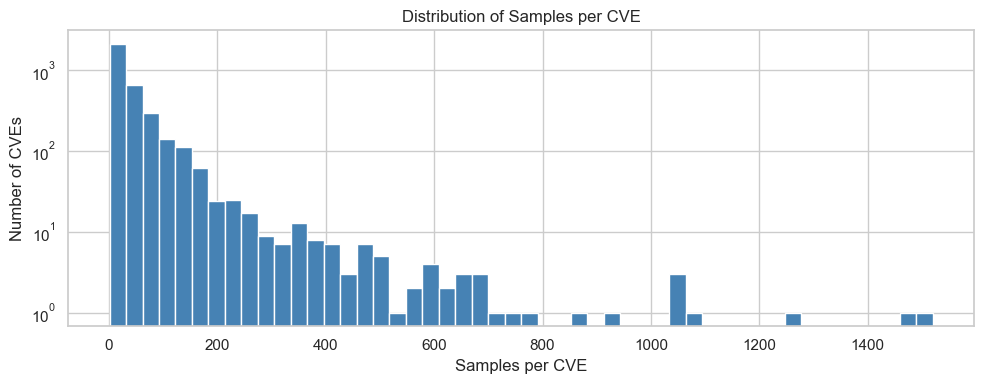

In [5]:
cve_counts = df.groupby("cve_id").agg(
    total=("vul", "count"),
    vulnerable=("vul", "sum"),
).reset_index()
cve_counts["benign"] = cve_counts["total"] - cve_counts["vulnerable"]
cve_counts["vul_ratio"] = cve_counts["vulnerable"] / cve_counts["total"]

print(f"Unique CVEs: {len(cve_counts):,}")
print(f"\nSamples per CVE:")
print(cve_counts["total"].describe().to_string())

fig, ax = plt.subplots(figsize=(10, 4))
ax.hist(cve_counts["total"], bins=50, color="steelblue", edgecolor="white")
ax.set_title("Distribution of Samples per CVE")
ax.set_xlabel("Samples per CVE")
ax.set_ylabel("Number of CVEs")
ax.set_yscale("log")
plt.tight_layout()
plt.show()

In [6]:
# Top 30 CVEs by sample count
top30_cves = cve_counts.nlargest(30, "total")[["cve_id", "total", "vulnerable", "benign", "vul_ratio"]].reset_index(drop=True)
top30_cves["vul_ratio"] = top30_cves["vul_ratio"].map("{:.1%}".format)
top30_cves

,cve_id,total,vulnerable,benign,vul_ratio
0,CVE-2016-5219,1520,12,1508,0.8%
1,CVE-2014-1713,1462,8,1454,0.5%
2,CVE-2011-2918,1259,74,1185,5.9%
3,CVE-2017-5120,1066,2,1064,0.2%
4,CVE-2012-2875,1057,28,1029,2.6%
5,CVE-2012-5148,1053,20,1033,1.9%
6,CVE-2013-7421,1049,1,1048,0.1%
7,CVE-2018-13006,931,6,925,0.6%
8,CVE-2017-9059,877,51,826,5.8%
9,CVE-2017-5019,768,7,761,0.9%


## 3. CWE Distribution

In [7]:
if "cwe_id" not in df.columns:
    print("CWE ID column not found — skipping CWE analysis")
else:
    cwe_counts = df.groupby("cwe_id").agg(
        total=("vul", "count"),
        vulnerable=("vul", "sum"),
    ).reset_index()
    cwe_counts["benign"] = cwe_counts["total"] - cwe_counts["vulnerable"]
    cwe_counts["vul_ratio"] = cwe_counts["vulnerable"] / cwe_counts["total"]
    cwe_counts = cwe_counts.sort_values("total", ascending=False).reset_index(drop=True)

    print(f"Unique CWEs: {len(cwe_counts):,}")
    print(f"\nSamples per CWE:")
    print(cwe_counts["total"].describe().to_string())

Unique CWEs: 91

Samples per CWE:
count       91.000000
mean      1675.065934
std       4260.617949
min          1.000000
25%         38.000000
50%         89.000000
75%        912.000000
max      26497.000000


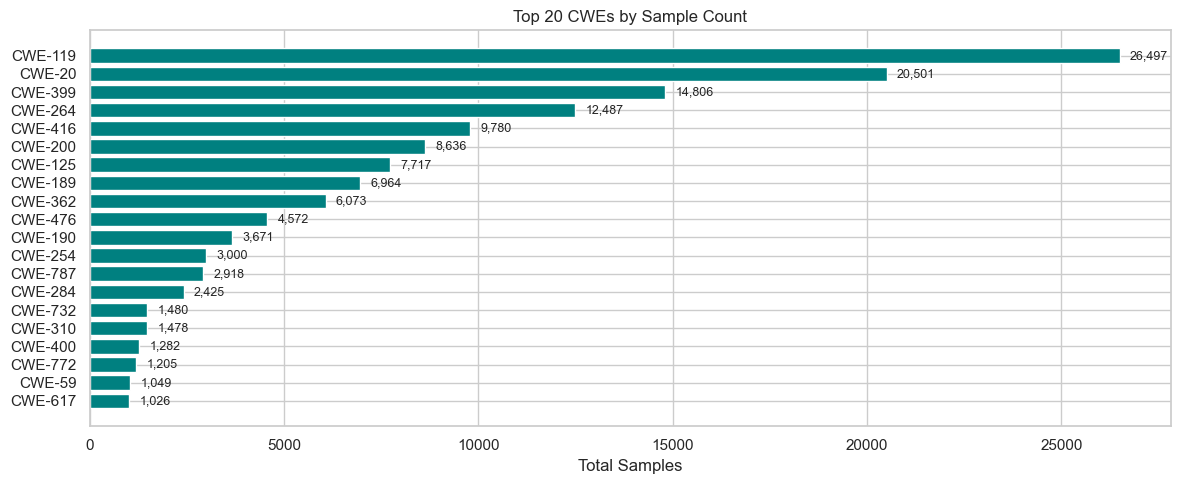

In [8]:
# Top 20 CWEs by sample count — bar chart
top20_cwes = cwe_counts.head(20)

fig, ax = plt.subplots(figsize=(12, 5))
ax.barh(top20_cwes["cwe_id"].iloc[::-1], top20_cwes["total"].iloc[::-1], color="teal")
ax.set_title("Top 20 CWEs by Sample Count")
ax.set_xlabel("Total Samples")
for i, (cwe, total) in enumerate(zip(top20_cwes["cwe_id"].iloc[::-1], top20_cwes["total"].iloc[::-1])):
    ax.text(total + max(top20_cwes["total"]) * 0.01, i, f"{total:,}", va="center", fontsize=9)
plt.tight_layout()
plt.show()

In [9]:
# Table: top 20 CWEs with class balance
top20_table = top20_cwes[["cwe_id", "total", "vulnerable", "benign", "vul_ratio"]].copy().reset_index(drop=True)
top20_table["vul_ratio"] = top20_table["vul_ratio"].map("{:.1%}".format)
top20_table

,cwe_id,total,vulnerable,benign,vul_ratio
0,CWE-119,26497,2127,24370,8.0%
1,CWE-20,20501,1142,19359,5.6%
2,CWE-399,14806,736,14070,5.0%
3,CWE-264,12487,508,11979,4.1%
4,CWE-416,9780,330,9450,3.4%
5,CWE-200,8636,503,8133,5.8%
6,CWE-125,7717,625,7092,8.1%
7,CWE-189,6964,337,6627,4.8%
8,CWE-362,6073,278,5795,4.6%
9,CWE-476,4572,215,4357,4.7%


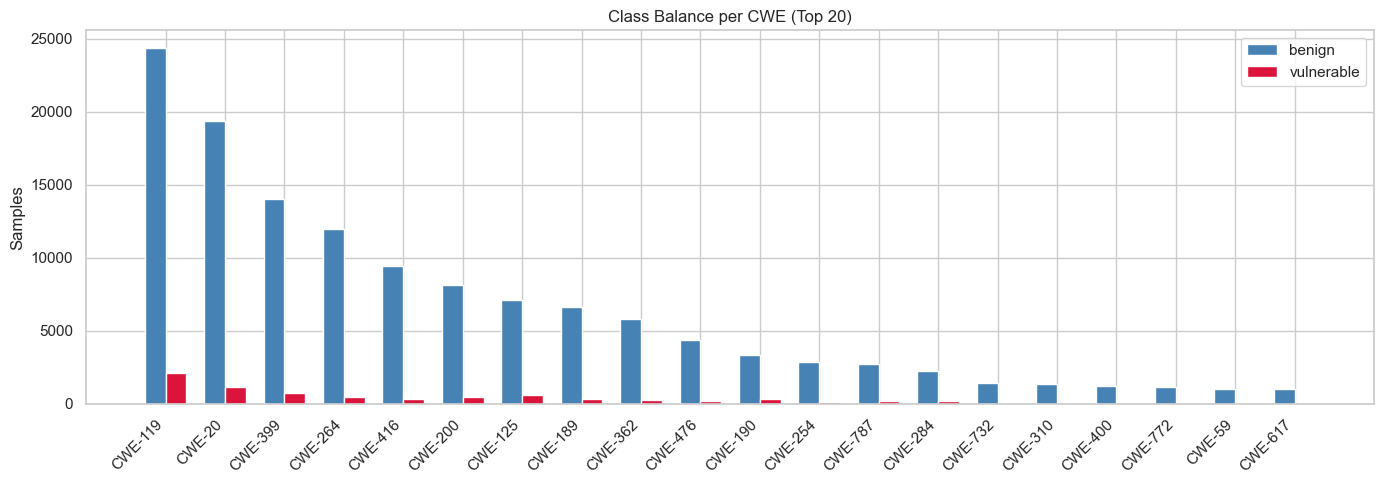

In [10]:
# Grouped bar chart: vulnerable vs benign for top 20 CWEs
fig, ax = plt.subplots(figsize=(14, 5))
x = np.arange(len(top20_cwes))
width = 0.35
ax.bar(x - width / 2, top20_cwes["benign"].values, width, label="benign", color="steelblue")
ax.bar(x + width / 2, top20_cwes["vulnerable"].values, width, label="vulnerable", color="crimson")
ax.set_xticks(x)
ax.set_xticklabels(top20_cwes["cwe_id"].values, rotation=45, ha="right")
ax.set_ylabel("Samples")
ax.set_title("Class Balance per CWE (Top 20)")
ax.legend()
plt.tight_layout()
plt.show()

## 4. Code Length Statistics

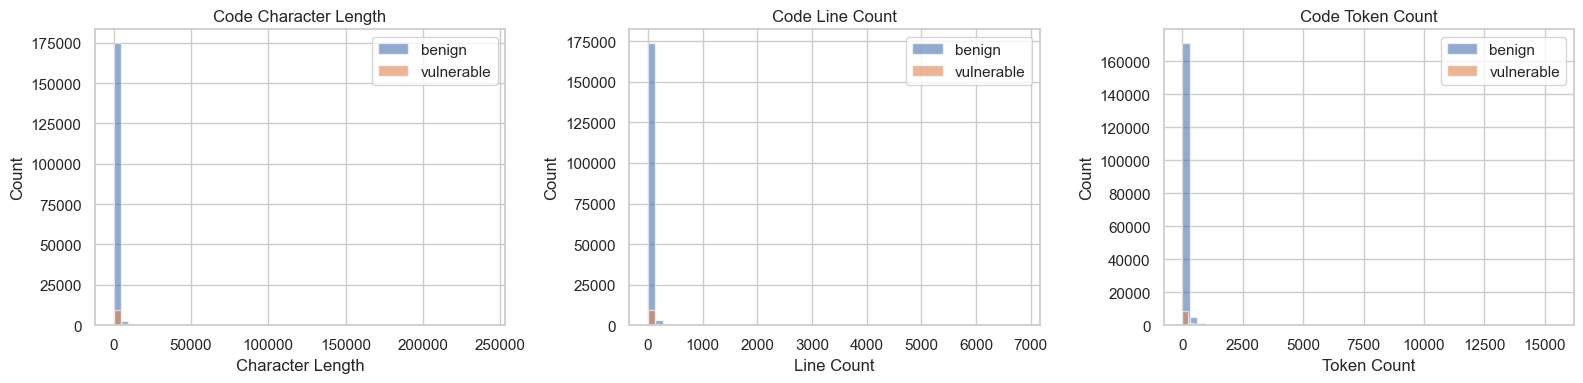

,code_char_len,code_line_count,code_token_count
count,188636.000000,188636.000000,188636.000000
mean,910.437371,30.934069,83.485215
std,2504.872643,76.167640,211.857585
min,14.000000,2.000000,2.000000
25%,193.000000,7.000000,15.000000
50%,395.000000,14.000000,33.000000
75%,873.000000,31.000000,80.000000
max,240969.000000,6820.000000,15441.000000


In [11]:
code = df["func_before"].dropna()
df["code_char_len"] = df["func_before"].str.len()
df["code_line_count"] = df["func_before"].str.count("\n") + 1
df["code_token_count"] = df["func_before"].str.split().str.len()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, title in zip(
    axes,
    ["code_char_len", "code_line_count", "code_token_count"],
    ["Character Length", "Line Count", "Token Count"],
):
    for label, group in df.groupby("vul"):
        name = "vulnerable" if label == 1 else "benign"
        ax.hist(group[col].dropna(), bins=50, alpha=0.6, label=name)
    ax.set_title(f"Code {title}")
    ax.set_xlabel(title)
    ax.set_ylabel("Count")
    ax.legend()
plt.tight_layout()
plt.show()

df[["code_char_len", "code_line_count", "code_token_count"]].describe()

## 5. CVE Description Statistics

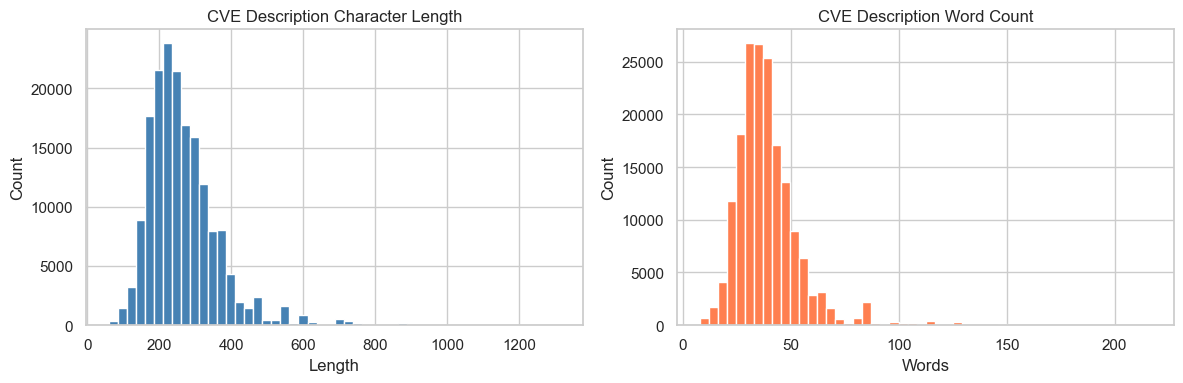

,desc_char_len,desc_word_count
count,174614.000000,174614.000000
mean,266.235926,39.257688
std,99.708812,15.205955
min,60.000000,8.000000
25%,202.000000,30.000000
50%,247.000000,37.000000
75%,309.000000,45.000000
max,1315.000000,217.000000


In [12]:
desc_col = "cve_desc" if "cve_desc" in df.columns else "Summary"
df["desc_char_len"] = df[desc_col].str.len()
df["desc_word_count"] = df[desc_col].str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df["desc_char_len"].dropna(), bins=50, color="steelblue", edgecolor="white")
axes[0].set_title("CVE Description Character Length")
axes[0].set_xlabel("Length")
axes[0].set_ylabel("Count")

axes[1].hist(df["desc_word_count"].dropna(), bins=50, color="coral", edgecolor="white")
axes[1].set_title("CVE Description Word Count")
axes[1].set_xlabel("Words")
axes[1].set_ylabel("Count")
plt.tight_layout()
plt.show()

df[["desc_char_len", "desc_word_count"]].describe()

## 6. Expansion Candidate Recommendations

CWEs with at least 200 vulnerable samples and at least 30% benign representation are candidates for POC expansion.

In [13]:
MIN_VUL_SAMPLES = 200
MIN_BENIGN_RATIO = 0.30

candidates = cwe_counts[
    (cwe_counts["vulnerable"] >= MIN_VUL_SAMPLES)
    & (cwe_counts["benign"] / cwe_counts["total"] >= MIN_BENIGN_RATIO)
].copy()
candidates["benign_ratio"] = (candidates["benign"] / candidates["total"]).map("{:.1%}".format)
candidates = candidates.sort_values("total", ascending=False).reset_index(drop=True)

display_cols = ["cwe_id", "total", "vulnerable", "benign", "benign_ratio"]
print(f"Found {len(candidates)} candidate CWEs for expansion (>={MIN_VUL_SAMPLES} vulnerable, >={MIN_BENIGN_RATIO:.0%} benign):\n")
candidates[display_cols]

Found 11 candidate CWEs for expansion (>=200 vulnerable, >=30% benign):



,cwe_id,total,vulnerable,benign,benign_ratio
0,CWE-119,26497,2127,24370,92.0%
1,CWE-20,20501,1142,19359,94.4%
2,CWE-399,14806,736,14070,95.0%
3,CWE-264,12487,508,11979,95.9%
4,CWE-416,9780,330,9450,96.6%
5,CWE-200,8636,503,8133,94.2%
6,CWE-125,7717,625,7092,91.9%
7,CWE-189,6964,337,6627,95.2%
8,CWE-362,6073,278,5795,95.4%
9,CWE-476,4572,215,4357,95.3%
